# 01 · MNIST 결과 보기

`exercise.py --run`이 저장한 `outputs/01_mnist/<실행이름>/`을 읽어 그림 3장을 그립니다. 학습 코드는 여기에 두지 않습니다.

먼저 `exercise.py`의 `save_results()`를 작성하고 `--run`을 실행하세요. matplotlib 기본 글꼴에는 한글이 없으므로 그림 안의 글자는 영어로 씁니다.

In [10]:
import json
import runpy

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
from torchvision import datasets

ns = runpy.run_path("../learning/01_mnist/exercise.py")  # exercise.py의 상수·함수를 불러옵니다
run_dir = ns["OUTPUT_DIR"] / ns["RUN_NAME"]  # 다른 실행은 ns["OUTPUT_DIR"] / "mlp_seed42"처럼 지정
run_dir

PosixPath('/home/minwoo/Develop/model-finetuning/outputs/01_mnist/cnn_seed42')

In [11]:
# TODO: run_dir / "metrics.json"은 metrics(dict)로, run_dir / "predictions.jsonl"은 한 줄씩 dict로 바꿔 predictions(list)로 읽으세요.

with open(run_dir / "metrics.json", 'r') as f:
    metrics = json.load(f)

with open(run_dir / "predictions.jsonl", 'r') as f:
    predictions = [json.loads(line) for line in f.readlines()]

## 1. 학습 곡선

loss가 내려가다 평평해지면 정상입니다. 끝까지 계속 내려가면 epoch을 늘려 볼 만합니다.

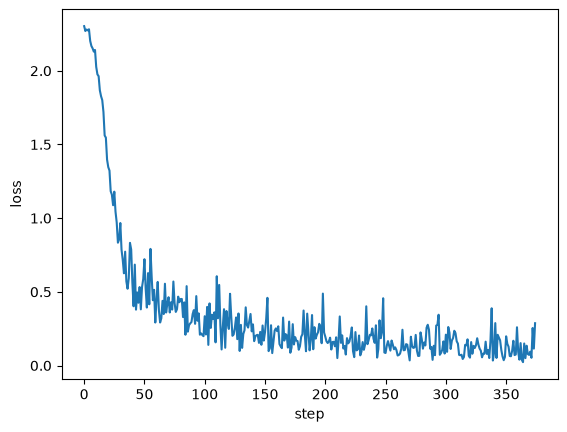

In [12]:
# TODO: metrics의 step별 train loss로 곡선을 그리고 run_dir / "train_loss.png"로 저장하세요.
# 힌트: fig, ax = plt.subplots() → ax.plot(...) → ax.set(xlabel=..., ylabel=...) → fig.savefig(...)

train_losses = metrics['train_losses']
X = range(len(train_losses))

fig, ax = plt.subplots() # 1개 plot을 그려도 사용할 수 있음 (그래프 요소들을 명확히 제어 가능)
ax.plot(X, train_losses)
ax.set(xlabel='step', ylabel='loss')
fig.show()
fig.savefig(run_dir / "train_loss.png") # 저장

## 2. 혼동행렬

대각선 밖에서 숫자가 큰 칸이 모델이 자주 헷갈리는 숫자 쌍입니다.

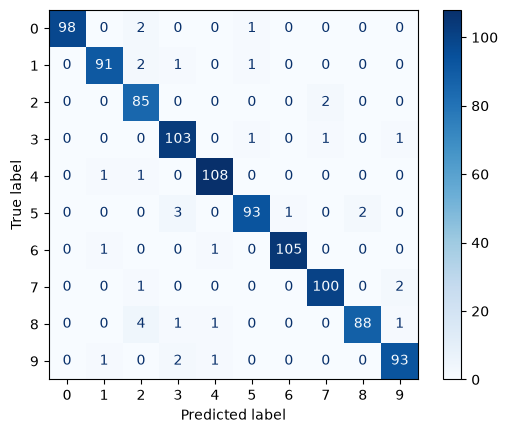

In [13]:
SPLIT = "validation"  # test는 설정을 다 고른 뒤 마지막에만 봅니다

# TODO: metrics[SPLIT]의 혼동행렬을 그리고 run_dir / f"confusion_{SPLIT}.png"로 저장하세요.
# 힌트: disp = ConfusionMatrixDisplay(np.array(...)).plot(cmap="Blues") → disp.figure_.savefig(...)

confusion_matrix = metrics[SPLIT]["confusion_matrix"]
disp = ConfusionMatrixDisplay(
    np.array(confusion_matrix)
).plot(cmap='Blues')
disp.figure_.savefig(run_dir / f"confusion_{SPLIT}.png")

## 3. 오답 20장

`results.md`의 실패 사례 칸에 옮길 근거입니다.

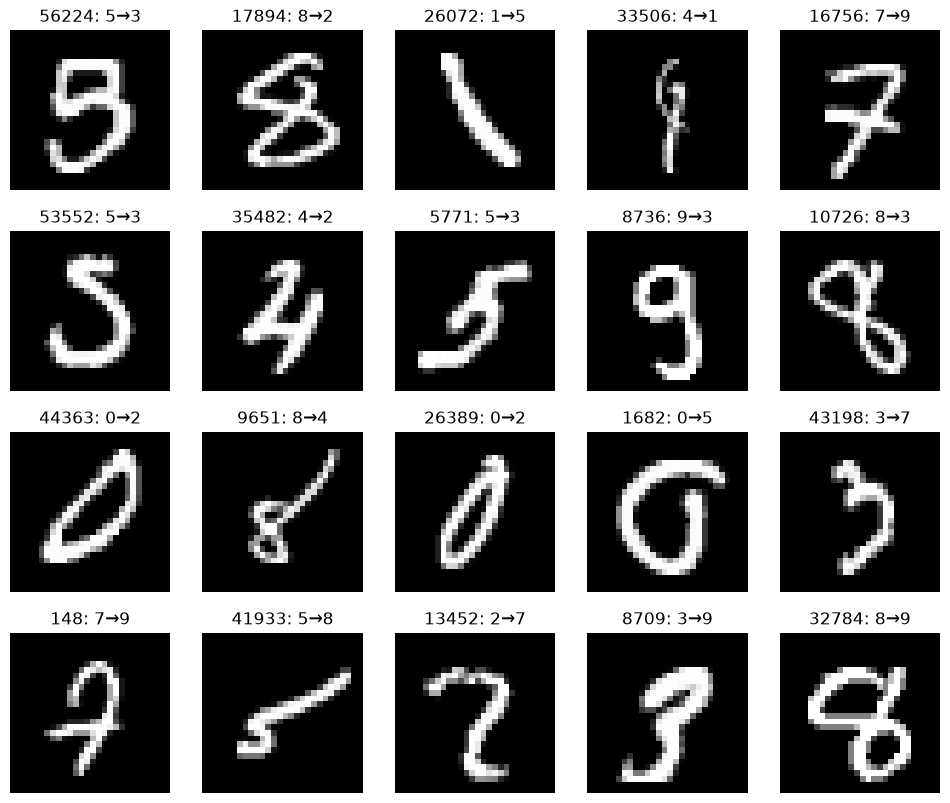

In [14]:
# validation 인덱스는 공식 train, test 인덱스는 공식 test 기준입니다.
mnist = datasets.MNIST(ns["DATA_DIR"], train=(SPLIT == "validation"))

# TODO: predictions에서 SPLIT의 오답만 골라 앞 20개를 4×5 격자로 그리고 run_dir / f"mistakes_{SPLIT}.png"로 저장하세요.
# 힌트: fig, axes = plt.subplots(4, 5) → image, _ = mnist[p["mnist_index"]] → ax.imshow(image, cmap="gray")
#       → ax.set_title(f"{p['label']}→{p['pred']}") → ax.axis("off")

wrong_answer = []
for prediction in predictions:
    if prediction['split'] != SPLIT:
        continue
    if prediction['label'] != prediction['pred']:
        wrong_answer.append(prediction)

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i, ax in enumerate(axes.flatten()):
    p = wrong_answer[i]
    image, _ = mnist[p["mnist_index"]]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"{p["mnist_index"]}: {p['label']}→{p['pred']}")
    ax.axis('off')

fig.savefig(run_dir / f"mistakes_{SPLIT}.png")

## 4. MLP vs CNN 비교

`results.md` 결과 표의 **95% CI** 칸과 표 아래 **paired bootstrap** 줄을 채웁니다. MLP·CNN 두 실행 결과가 모두 있어야 합니다.

- Wilson 구간: 모델 하나의 정확도가 어떤 1,000장이 뽑혔느냐에 따라 얼마나 흔들리는지
- paired bootstrap: **같은 이미지끼리** 비교한 두 모델의 정확도 차이가 얼마나 흔들리는지. 구간 전체가 0보다 크면 개선

In [15]:
from scipy.stats import binomtest

BASELINE, COMPARE = "mlp_seed42", "cnn_seed42"
COMPARE_SPLIT = "test"  # results.md 결과 표는 고정 test 기준

# TODO: 두 실행의 predictions.jsonl에서 COMPARE_SPLIT 줄만 읽어 {mnist_index: row} dict로 만드세요.
# 힌트: 셀 2처럼 json.loads로 읽고, row["split"] == COMPARE_SPLIT인 줄만 남깁니다. 경로는 ns["OUTPUT_DIR"] / BASELINE / ...
with open(ns["OUTPUT_DIR"] / BASELINE / "predictions.jsonl", 'r') as f:
    baseline = {}
    for line in f.readlines():
        line = json.loads(line)
        if line['split'] == COMPARE_SPLIT:
            baseline[line['mnist_index']] = line

with open(ns["OUTPUT_DIR"] / COMPARE / "predictions.jsonl", 'r') as f:
    compare = {}
    for line in f.readlines():
        line = json.loads(line)
        if line['split'] == COMPARE_SPLIT:
            compare[line['mnist_index']] = line

# 다 채운 뒤 주석을 풀어 확인: 두 실행이 같은 이미지로 평가됐는지 (paired 비교의 전제)
assert baseline.keys() == compare.keys()

In [16]:
# TODO: 같은 mnist_index 순서로, 맞으면 1·틀리면 0인 numpy 배열 두 개를 만드세요.
keys = sorted(baseline)
baseline_correct = []
compare_correct = []

for key in keys:
    if baseline[key]['label'] == baseline[key]['pred']:
        baseline_correct.append(1)
    else:
        baseline_correct.append(0)

    if compare[key]['label'] == compare[key]['pred']:
        compare_correct.append(1)
    else:
        compare_correct.append(0)

baseline_correct = np.array(baseline_correct)
compare_correct = np.array(compare_correct)

# TODO: 두 모델의 Wilson 95% 구간을 출력하세요 → results.md 결과 표의 95% CI 칸
# 힌트: ci = binomtest(int(정답 수), n).proportion_ci(method="wilson") → ci.low, ci.high
baseline_ci = binomtest(int(baseline_correct.sum()), len(baseline_correct)).proportion_ci(method='wilson')
compare_ci = binomtest(int(compare_correct.sum()), len(compare_correct)).proportion_ci(method='wilson')
print(f"Baseline CI: [{baseline_ci.low:.3f}, {baseline_ci.high:.3f}]")
print(f"Compare CI: [{compare_ci.low:.3f}, {compare_ci.high:.3f}]")

# TODO: 둘 다 맞음 / COMPARE만 맞음 / BASELINE만 맞음 / 둘 다 틀림 개수를 세세요 → 실패 사례 고를 때 사용
# 힌트: ((baseline_correct == 0) & (compare_correct == 1)).sum()처럼 조건을 묶어 셉니다.
print("Both Correct: ", ((baseline_correct==1) & (compare_correct==1)).sum())
print("Baseline Correct: ", ((baseline_correct==1) & (compare_correct==0)).sum())
print("Compare Correct: ", ((baseline_correct==0) & (compare_correct==1)).sum())
print("Both Wrong: ", ((baseline_correct==0) & (compare_correct==0)).sum())

Baseline CI: [0.909, 0.942]
Compare CI: [0.951, 0.974]
Both Correct:  913
Baseline Correct:  14
Compare Correct:  51
Both Wrong:  22


### paired bootstrap

"test 1,000장을 다시 뽑았다면 차이가 어떻게 나왔을까"를 흉내 냅니다. 1,000장에서 **복원추출**로 1,000장을 다시 뽑고, 두 모델을 **같은 이미지들**로 채점해 차이를 잽니다. 이걸 10,000번 반복하면 차이의 분포가 생기고, 그 가운데 95%가 신뢰구간입니다.

In [17]:
N_BOOTSTRAP = 10_000
rng = np.random.default_rng(0)  # seed를 고정해야 다시 실행해도 같은 구간이 나옵니다
n = len(keys)

# TODO: (COMPARE − BASELINE) 정확도 차이를 N_BOOTSTRAP번 계산해 diffs(numpy 배열)에 모으세요.
# 1. idx = rng.integers(0, n, size=n)  → 위치 n개를 복원추출 (같은 위치가 여러 번 나올 수 있음)
# 2. 두 배열에 '같은' idx를 씁니다: compare_correct[idx].mean() - baseline_correct[idx].mean()
#    모델마다 따로 뽑으면 paired가 아닙니다.
diffs = []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n, size=n)
    diffs.append(compare_correct[idx].mean() - baseline_correct[idx].mean())
diffs = np.array(diffs, dtype=np.float32)

# TODO: 실제 차이(원래 1,000장 기준)와 np.percentile(diffs, [2.5, 97.5])를 출력하세요 → results.md 표 아래 줄
# 검산: 2026-10-21에 저장된 결과로는 차이 +0.037, 구간 약 [+0.022, +0.053]
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"Real Diff: {compare_correct.mean() - baseline_correct.mean():.3f}")
print(f"Bootstrap: [{low:.3f}, {high:.3f}]")

Real Diff: 0.037
Bootstrap: [0.022, 0.053]


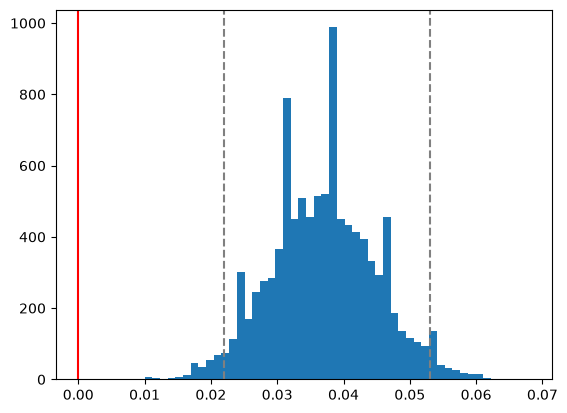

In [18]:
# TODO (선택): diffs 히스토그램을 그리고 0 위치에 세로선을 그어, 구간이 0을 넘는지 눈으로 확인하세요.
# 힌트: ax.hist(diffs, bins=50) → ax.axvline(0, color="red") → ax.axvline(하한·상한, linestyle="--")
#       → fig.savefig(ns["OUTPUT_DIR"] / f"bootstrap_{COMPARE_SPLIT}.png")  # 두 실행 비교라 실행 폴더 밖에 저장

fig, ax = plt.subplots()
ax.hist(diffs, bins=50)
ax.axvline(0, color="red")
ax.axvline(low, linestyle='--', color='grey')
ax.axvline(high, linestyle='--', color='grey')
fig.show()